In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [32]:
df = pd.read_csv('../dataset/raw/AmesHousing.csv')

In [33]:
print(f"Dimensions du dataset : {df.shape}")
print("-" * 30)
# Affiche un résumé des types et des valeurs nulles
df.info()

Dimensions du dataset : (2930, 82)
------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 

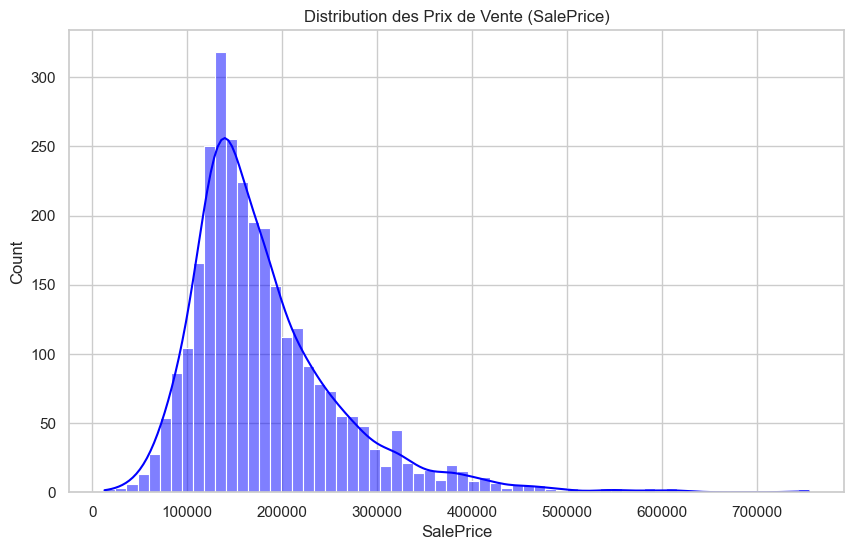

Skewness (Asymétrie) : 1.7435000757376466
Kurtosis (Aplatissement) : 5.118899951130896


In [34]:

sns.set(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(df['SalePrice'], kde=True, color='blue')
plt.title('Distribution des Prix de Vente (SalePrice)')
plt.show()

print(f"Skewness (Asymétrie) : {df['SalePrice'].skew()}")
print(f"Kurtosis (Aplatissement) : {df['SalePrice'].kurt()}")


In [35]:
# Calcul du pourcentage de données manquantes
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])

# Affiche les 20 pires colonnes
print(missing_data.head(20))


                Total   Percent
Pool QC          2917  0.995563
Misc Feature     2824  0.963823
Alley            2732  0.932423
Fence            2358  0.804778
Mas Vnr Type     1775  0.605802
Fireplace Qu     1422  0.485324
Lot Frontage      490  0.167235
Garage Qual       159  0.054266
Garage Yr Blt     159  0.054266
Garage Cond       159  0.054266
Garage Finish     159  0.054266
Garage Type       157  0.053584
Bsmt Exposure      83  0.028328
BsmtFin Type 2     81  0.027645
Bsmt Qual          80  0.027304
Bsmt Cond          80  0.027304
BsmtFin Type 1     80  0.027304
Mas Vnr Area       23  0.007850
Bsmt Full Bath      2  0.000683
Bsmt Half Bath      2  0.000683


In [36]:
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [37]:
# pour voir la relation entre le prix en gnrl entre differentes variables 
# seul contrainte est que les var doivent etre de type numerique 
# donc :
#     correlation positive entre les deux variables (quand une monte l'autre le fait)
#     correlation nulle aucun lien
#     correlation negative (quand l'une monte l'autre descend)                                               

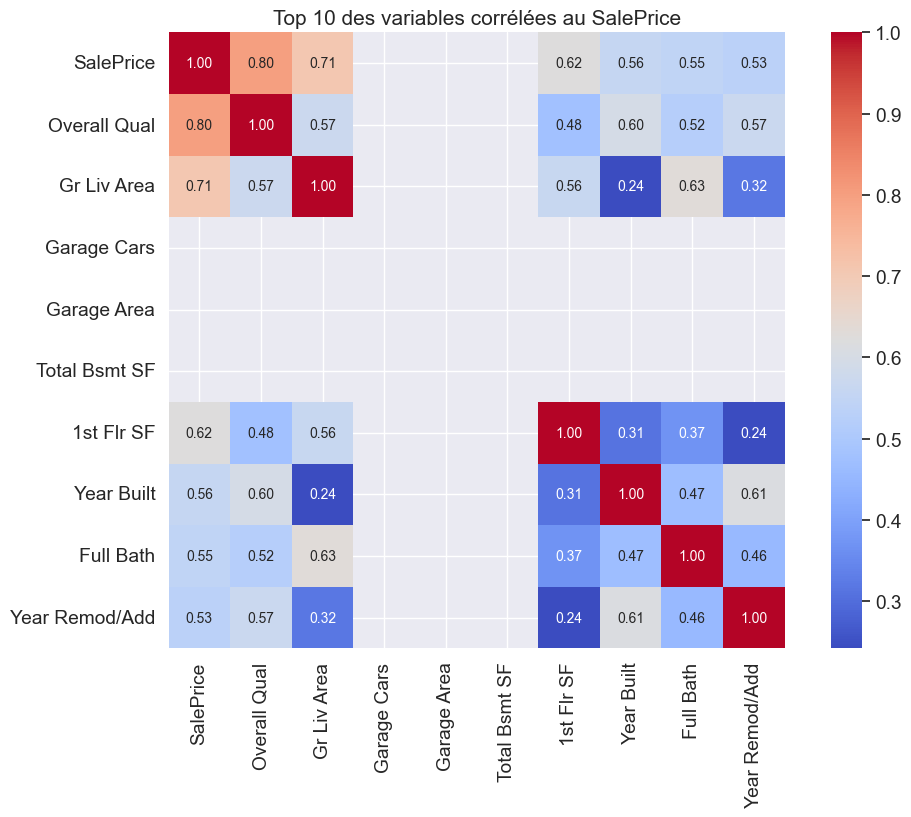

In [38]:
# On ne calcule la corrélation que sur les colonnes numériques
corr_matrix = df.select_dtypes(include=[np.number]).corr()

# Zoom sur les 10 variables les plus corrélées au Prix (SalePrice)
k = 10 
cols = corr_matrix.nlargest(k, 'SalePrice')['SalePrice'].index

plt.figure(figsize=(12, 8))
cm = np.corrcoef(df[cols].values.T)
sns.set(font_scale=1.25)
# Heatmap annotée
sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f', annot_kws={'size': 10}, 
            yticklabels=cols.values, xticklabels=cols.values, cmap='coolwarm')
plt.title('Top 10 des variables corrélées au SalePrice')
plt.show()


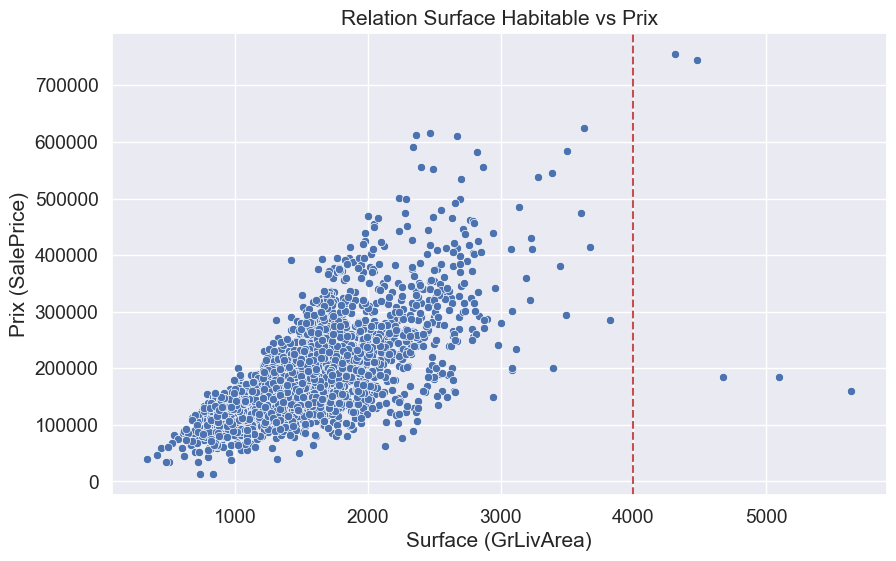

In [39]:
# GrLivArea = Surface habitable au dessus du sol
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['Gr Liv Area'], y=df['SalePrice'])
plt.title('Relation Surface Habitable vs Prix')
plt.xlabel('Surface (GrLivArea)')
plt.ylabel('Prix (SalePrice)')

# On trace des lignes pour t'aider à repérer les anomalies
plt.axvline(x=4000, color='r', linestyle='--') # Limite suspecte souvent observée
plt.show()


In [40]:
# dans le graphique d'en haut en voit des valeurs extremes que la matrice de correlation ne peut montrer
# ici dans notre cas des maisons avec des surfaces immenses vendues avec des prix 
# de rien du tout

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18884\3001140743.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Bsmt Exposure', y='SalePrice', data=df, palette='viridis')


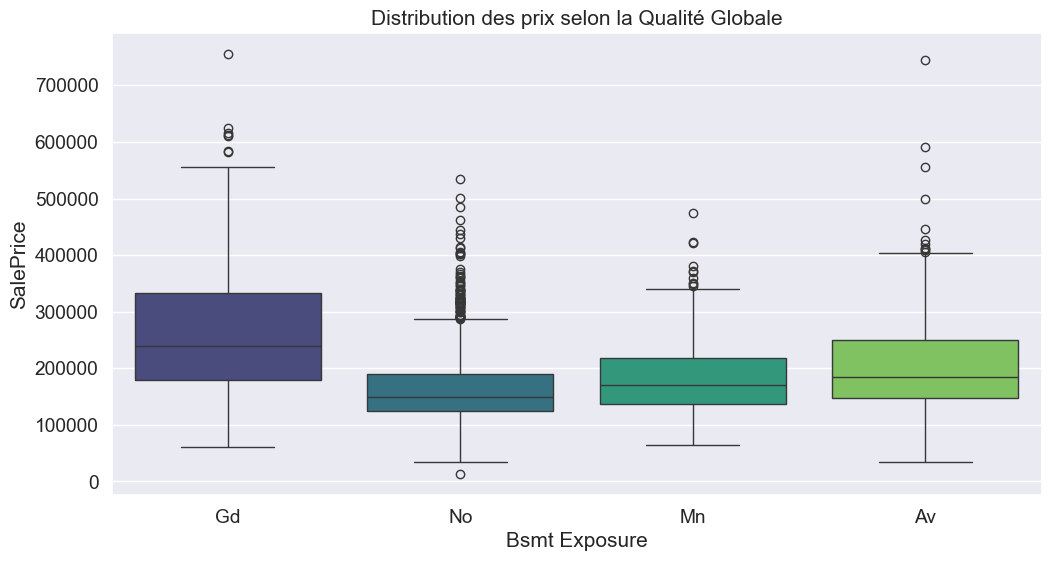

In [41]:
# OverallQual : Note de 1 à 10 de la qualité globale
plt.figure(figsize=(12, 6))
sns.boxplot(x='Bsmt Exposure', y='SalePrice', data=df, palette='viridis')
plt.title('Distribution des prix selon la Qualité Globale')
plt.show()


In [42]:
# pour le code d'en haut c'est pour verifier les distribution mais plutot pour les
# variables qui ne sont pas de type entier dans ce cas chaine de char

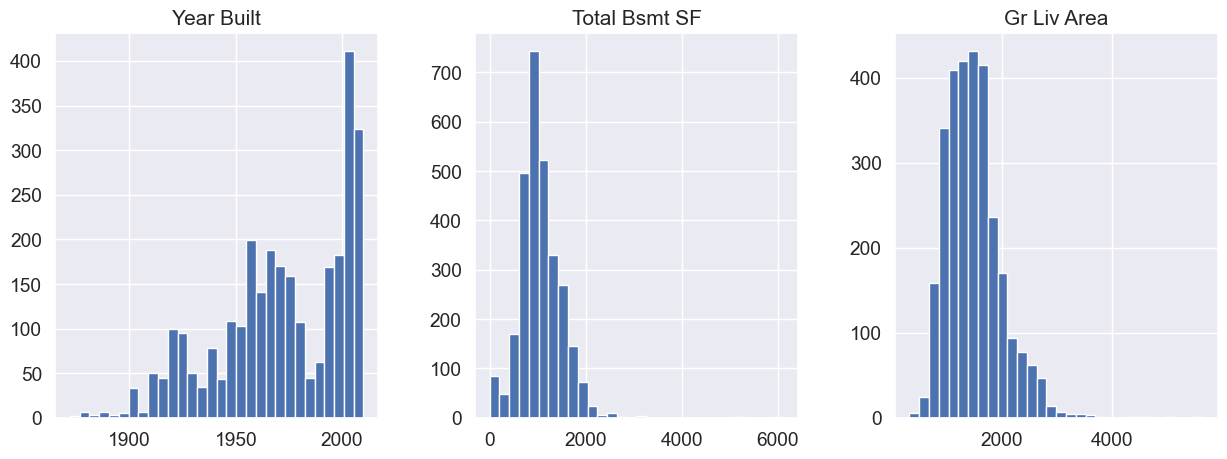

In [43]:
# Afficher l'histogramme de quelques variables clés
cols_to_check = ['Year Built', 'Total Bsmt SF', 'Gr Liv Area']
df[cols_to_check].hist(bins=30, figsize=(15, 5), layout=(1, 3))
plt.show()


In [44]:
# dans le code d'en haut on verifie nos entree pour verifier
# les classes minoritaire 
# EX: pour les maison construite en 1900 on a moins de 50 entree

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18884\1153606772.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Overall Qual', y='SalePrice', data=df, palette='viridis')


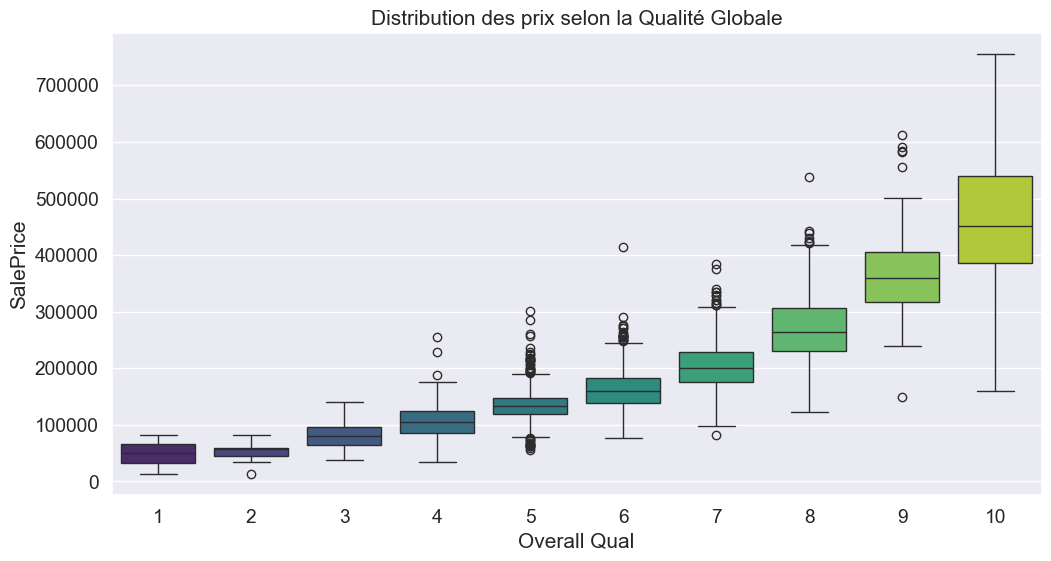

In [45]:
# OverallQual : Note de 1 à 10 de la qualité globale
plt.figure(figsize=(12, 6))
sns.boxplot(x='Overall Qual', y='SalePrice', data=df, palette='viridis')
plt.title('Distribution des prix selon la Qualité Globale')
plt.show()


In [46]:
# Suppression des outliers (Grande surface mais petit prix)
# On filtre : On garde ceux qui sont SOIT plus petits que 4000, SOIT chers (> 300000)
# Mais la règle simple recommandée est : Supprimer ceux > 4000 sq ft avec SalePrice < 300000
# Vérifions les index avant suppression si tu veux être sûr, mais voici la commande directe :

In [47]:
df = df.drop(df[(df['Gr Liv Area'] > 4000) & (df['SalePrice'] < 300000)].index)

print(f"Nouvelle taille du dataset : {df.shape}")


Nouvelle taille du dataset : (2927, 82)


In [48]:
# normalisation de la variable cible vu que 
# l'aplatissement etait de 5 ce qui est tres grand

In [49]:
# Transformation Log
df["SalePrice"] = np.log1p(df["SalePrice"])

# Vérification rapide
print(f"Nouvelle Skewness : {df['SalePrice'].skew()}")



Nouvelle Skewness : -0.014352823060404227


In [50]:
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,12.278398
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,11.561725
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,12.055256
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,12.404928
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,12.154258


In [ ]:
# ici on commance le traitement de donnees

In [56]:

# --- 1. Sauvegarde de l'ID ---
# On garde les ID pour la soumission finale, mais ils ne servent pas à prédire
train_ID = df['PID']
df.drop("PID", axis = 1, inplace = True)



KeyError: 'PID'

In [ ]:
# ici la plus part des elements nan veulent simpleument dire non par exemple 
# un nan dans piscine signifie non

In [55]:
# --- 2. Traitement des "Faux" Manquants (NaN = Pas d'équipement) ---
# Liste des colonnes où NaN signifie "None"
cols_fill_none = ['Pool QC', 'Misc Feature', 'Alley', 'Fence', 'Fireplace Qu',
                  'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond',
                  'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2']

for col in cols_fill_none:
    df[col] = df[col].fillna('None')


In [58]:
# --- 3. Cas particulier : LotFrontage ---
# On remplit par la médiane du quartier
df["Lot Frontage"] = df.groupby("Neighborhood")["Lot Frontage"].transform(
    lambda x: x.fillna(x.median()))




c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


In [ ]:
# ici aussi dans le code suivant on a des faux nan
# car si on a pas de garage ce serait un 0 non un nan

In [ ]:

cols_fill_0 = ['Garage Yr Blt', 'Garage Area', 'Garage Cars',
               'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF','Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath']

for col in cols_fill_0:
    df[col] = df[col].fillna(0)



In [61]:
# --- 5. Les Manquants Restants (Mode) ---
# Pour le reste (Electrical, MasVnrType...), on met la valeur la plus fréquente
cols_remaining = ['MS Zoning', 'Electrical', 'Kitchen Qual', 'Exterior 1st', 'Exterior 2nd', 'Sale Type', 'Mas Vnr Type']
for col in cols_remaining:
    df[col] = df[col].fillna(df[col].mode()[0]) # mode()[0] prend la 1ère valeur la plus fréquente


In [62]:
# --- 6. Vérification finale ---
# Il ne devrait plus rester de NaN
print("Valeurs manquantes restantes :", df.isnull().sum().max())

Valeurs manquantes restantes : 23


In [63]:
# Calcul du pourcentage de données manquantes
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])

# Affiche les 20 pires colonnes
print(missing_data.head(20))

              Total   Percent
Mas Vnr Area     23  0.007858
Lot Frontage      3  0.001025
Order             0  0.000000
MS Zoning         0  0.000000
MS SubClass       0  0.000000
Street            0  0.000000
Alley             0  0.000000
Lot Shape         0  0.000000
Lot Area          0  0.000000
Utilities         0  0.000000
Lot Config        0  0.000000
Land Slope        0  0.000000
Neighborhood      0  0.000000
Condition 1       0  0.000000
Condition 2       0  0.000000
Bldg Type         0  0.000000
Land Contour      0  0.000000
House Style       0  0.000000
Overall Qual      0  0.000000
Year Built        0  0.000000


In [ ]:
# --- Correctif de sécurité ---

# 1. MasVnrArea : On remplit par 0
df['Mas Vnr Area'] = df['Mas Vnr Area'].fillna(0)

# 2. LotFrontage : Pour les derniers résistants, on prend la médiane globale
df['Lot Frontage'] = df['Lot Frontage'].fillna(df['Lot Frontage'].median())

# 3. Vérification 
nan_count = df.isnull().sum().sum()
print(f"Nombre total de NaN restants : {nan_count}")



Nombre total de NaN restants : 0


In [ ]:
# maintenant on essaie de creer des variables qui nous donneront 
# une forte correlation avec le prix
# et nous permettent de bien alleger le dataset

In [69]:
# 1. Création de la surface totale (Très forte corrélation attendue)
df['TotalSF'] = df['Total Bsmt SF'] + df['1st Flr SF'] + df['2nd Flr SF']

# 2. Simplification de certaines variables
# Exemple : Y a-t-il une piscine ? (Oui/Non) au lieu de la qualité
df['HasPool'] = df['Pool Area'].apply(lambda x: 1 if x > 0 else 0)

# 3. Certaines variables numériques sont en fait des catégories !
# MSSubClass (Type de logement : 20, 30, 40...) ce sont des codes, pas des quantités.
# On les transforme en texte pour qu'elles soient traitées comme des catégories plus tard.
df['MS SubClass'] = df['MS SubClass'].apply(str)
df['Overall Cond'] = df['Overall Cond'].astype(str) # La condition est souvent traitée comme cat
df['Yr Sold'] = df['Yr Sold'].astype(str)
df['Mo Sold'] = df['Mo Sold'].astype(str)


In [ ]:
# maintenant on doit encoder nos valeurs 

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2927 entries, 0 to 2929
Data columns (total 83 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2927 non-null   int64  
 1   MS SubClass      2927 non-null   object 
 2   MS Zoning        2927 non-null   object 
 3   Lot Frontage     2927 non-null   float64
 4   Lot Area         2927 non-null   int64  
 5   Street           2927 non-null   object 
 6   Alley            2927 non-null   object 
 7   Lot Shape        2927 non-null   object 
 8   Land Contour     2927 non-null   object 
 9   Utilities        2927 non-null   object 
 10  Lot Config       2927 non-null   object 
 11  Land Slope       2927 non-null   object 
 12  Neighborhood     2927 non-null   object 
 13  Condition 1      2927 non-null   object 
 14  Condition 2      2927 non-null   object 
 15  Bldg Type        2927 non-null   object 
 16  House Style      2927 non-null   object 
 17  Overall Qual     29

In [73]:


# A. Label Encoding pour les variables avec un ordre (Qualité)
cols_ordinal = ('Fireplace Qu', 'Bsmt Qual', 'Bsmt Cond', 'Garage Qual', 'Garage Cond', 
                'Exter Qual', 'Exter Cond','Heating QC', 'Pool QC', 'Kitchen Qual', 'BsmtFin Type 1', 
                'BsmtFin Type 2', 'Functional', 'Fence', 'Bsmt Exposure', 'Garage Finish', 'Land Slope',
                'Lot Shape', 'Paved Drive', 'Street', 'Alley', 'Central Air', 'MS SubClass', 'Overall Cond', 
                'Yr Sold', 'Mo Sold')

# On applique l'encodeur
for c in cols_ordinal:
    lbl = LabelEncoder() 
    lbl.fit(list(df[c].values)) 
    df[c] = lbl.transform(list(df[c].values))

print(f"Shape après Label Encoding: {df.shape}")

# B. One-Hot Encoding pour tout le reste (Quartier, Type de toit...)
# pandas a une fonction magique pour ça : get_dummies
df = pd.get_dummies(df)

print(f"Shape après One-Hot Encoding (Final): {df.shape}")


Shape après Label Encoding: (2927, 83)
Shape après One-Hot Encoding (Final): (2927, 234)


In [74]:
df.head()

,Order,MS SubClass,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Slope,Overall Qual,Overall Cond,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,1,5,141.0,31770,1,1,0,0,6,4,...,False,False,False,True,False,False,False,False,True,False
1,2,5,80.0,11622,1,1,3,0,5,5,...,False,False,False,True,False,False,False,False,True,False
2,3,5,81.0,14267,1,1,0,0,6,5,...,False,False,False,True,False,False,False,False,True,False
3,4,5,93.0,11160,1,1,3,0,7,4,...,False,False,False,True,False,False,False,False,True,False
4,5,10,74.0,13830,1,1,0,0,5,4,...,False,False,False,True,False,False,False,False,True,False


In [75]:
# Sauvegarde dans data/processed
df.to_csv('../dataset/traite/train_cleaned.csv', index=False)
print("Fichier nettoyé sauvegardé avec succès.")


Fichier nettoyé sauvegardé avec succès.
